In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install transformers emoji sentencepiece -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 23.2 MB/s eta 0:00:00


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torch.optim import AdamW
from transformers import (
	AutoTokenizer,
	AutoModelForSequenceClassification,
)
from tqdm import tqdm
import re
import emoji as emoji_lib

from datetime import datetime
RUN_ID = datetime.now().strftime('%m%d_%H%M')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
	print(f'GPU: {torch.cuda.get_device_name(0)}')
	print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM: 102.0 GB


In [ ]:
DRIVE_BASE  = '/content/drive/MyDrive/Materials (Spring 2026)/CIL'   
DATA_DIR    = f'{DRIVE_BASE}/sentiment-classification-data-256/data1'
CKPT_DIR    = f'{DRIVE_BASE}/checkpoints'
ENC_DIR     = f'{DRIVE_BASE}/encodings'
OUTPUT_DIR  = f'{DRIVE_BASE}/outputs'

for d in [CKPT_DIR, ENC_DIR, OUTPUT_DIR]:
	os.makedirs(d, exist_ok=True)

PREPROCESSING_MODE = 'sep'

NORMALIZE_EMOJIS = False

MODEL_NAME = 'xlm-roberta-large'

NUM_EPOCHS  = 10
LR          = 1e-6
BATCH_SIZE  = 64   
MAX_LENGTH  = 256
VAL_SIZE    = 0.10
NUM_WORKERS = 2    

print(f'PREPROCESSING_MODE : {PREPROCESSING_MODE}')
print(f'NORMALIZE_EMOJIS   : {NORMALIZE_EMOJIS}')
print(f'MODEL_NAME         : {MODEL_NAME}')
print(f'BATCH_SIZE         : {BATCH_SIZE}')

PREPROCESSING_MODE : sep
NORMALIZE_EMOJIS   : False
MODEL_NAME         : xlm-roberta-large
BATCH_SIZE         : 64


In [ ]:
train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f'Train: {len(train_df):,} rows | Test: {len(test_df):,} rows')
print(train_df['label'].value_counts().sort_index())
train_df.head(3)

Train: 252,000 rows | Test: 168,000 rows
label
0    50400
1    50400
2    50400
3    50400
4    50400
Name: count, dtype: int64


,id,sentence,label
0,0,Moderner Weihnachtsbaum in weiß\n\nDieses Jahr...,4
1,1,Passt wie angegossen\n\nTasche kam schnell und...,4
2,2,Schlechte Qualität\n\nIch habe sehr lange auf ...,1


In [ ]:
def normalize_emojis_fn(text: str) -> str:
	text = emoji_lib.demojize(text, delimiters=(' ', ' '))
	text = re.sub(r':(\w+):', r'\1', text)
	text = text.replace('_', ' ')
	return text

def split_title_body(text: str):
	parts = text.split('\n\n', 1)
	if len(parts) == 2:
		return parts[0].strip(), parts[1].strip()
	return text.strip(), ''

def preprocess(text: str):
	if NORMALIZE_EMOJIS:
		text = normalize_emojis_fn(text)
	title, body = split_title_body(text)
	title = re.sub(r'\s+', ' ', title).strip()
	body  = re.sub(r'\s+', ' ', body).strip()
	return title, body

train_df[['title', 'body']] = train_df['sentence'].apply(
	lambda t: pd.Series(preprocess(t))
)
test_df[['title', 'body']] = test_df['sentence'].apply(
	lambda t: pd.Series(preprocess(t))
)

print(f"Reviews with body : {(train_df['body'] != '').sum():,} ({(train_df['body'] != '').mean()*100:.1f}%)")
print(f"\nExample:")
print(f"  TITLE : {train_df['title'].iloc[0]}")
print(f"  BODY  : {train_df['body'].iloc[0][:100]}...")

Reviews with body : 252,000 (100.0%)

Example:
  TITLE : Moderner Weihnachtsbaum in weiß
  BODY  : Dieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß ent...


In [ ]:
(train_titles, val_titles,
 train_bodies, val_bodies,
 train_labels, val_labels) = train_test_split(
	train_df['title'].tolist(),
	train_df['body'].tolist(),
	train_df['label'].tolist(),
	test_size=VAL_SIZE,
	random_state=SEED,
	stratify=train_df['label'].tolist(),
)
print(f'Train: {len(train_titles):,} | Val: {len(val_titles):,}')

Train: 226,800 | Val: 25,200


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

safe_name = MODEL_NAME.replace('/', '-')
enc_prefix = f'{ENC_DIR}/{safe_name}_{PREPROCESSING_MODE}'

def tokenize(titles, bodies):
	if PREPROCESSING_MODE == 'sep':
		return tokenizer(
			titles,
			[b if b else ' ' for b in bodies],
			truncation=True, padding=True,
			max_length=MAX_LENGTH, return_tensors='pt',
		)
	else:
		texts = [t + (' ' + b if b else '') for t, b in zip(titles, bodies)]
		return tokenizer(
			texts,
			truncation=True, padding=True,
			max_length=MAX_LENGTH, return_tensors='pt',
		)

if not os.path.exists(f'{enc_prefix}_train.pt'):
	print('Tokenizing — this takes a few minutes...')
	train_enc = tokenize(train_titles, train_bodies)
	val_enc   = tokenize(val_titles,   val_bodies)
	test_enc  = tokenize(test_df['title'].tolist(), test_df['body'].tolist())
	torch.save(train_enc, f'{enc_prefix}_train.pt')
	torch.save(val_enc,   f'{enc_prefix}_val.pt')
	torch.save(test_enc,  f'{enc_prefix}_test.pt')
	print('Encodings saved to Drive.')
else:
	print('Loading cached encodings from Drive...')
	train_enc = torch.load(f'{enc_prefix}_train.pt', weights_only=False)
	val_enc   = torch.load(f'{enc_prefix}_val.pt',   weights_only=False)
	test_enc  = torch.load(f'{enc_prefix}_test.pt',  weights_only=False)

print(f'train : {train_enc["input_ids"].shape}')
print(f'val   : {val_enc["input_ids"].shape}')
print(f'test  : {test_enc["input_ids"].shape}')

decoded = tokenizer.decode(train_enc['input_ids'][0], skip_special_tokens=False)
print(f'\nDecoded example (first 200 chars):\n{decoded[:200]}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizing — this takes a few minutes...
Encodings saved to Drive.
train : torch.Size([226800, 256])
val   : torch.Size([25200, 256])
test  : torch.Size([168000, 256])

Decoded example (first 200 chars):
<s> :-)</s> Ich bin sehr zufrieden aber es könnte noch eine mittlere Reibe geben.</s><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad>


In [ ]:
class ReviewsDataset(Dataset):
	def __init__(self, encodings, labels):
		self.encodings = encodings
		self.labels    = labels

	def __getitem__(self, idx):
		item = {key: val[idx].clone() for key, val in self.encodings.items()}
		item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
		return item

	def __len__(self):
		return len(self.labels)

train_loader = DataLoader(ReviewsDataset(train_enc, train_labels),
						   batch_size=BATCH_SIZE, shuffle=True,
						   num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(ReviewsDataset(val_enc,   val_labels),
						   batch_size=BATCH_SIZE, shuffle=False,
						   num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(ReviewsDataset(test_enc,  [-1] * len(test_df)),
						   batch_size=BATCH_SIZE, shuffle=False,
						   num_workers=NUM_WORKERS, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')

Train batches: 3544 | Val batches: 394


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
if torch.cuda.device_count() > 1:
	print(f'Using DataParallel across {torch.cuda.device_count()} GPUs')
	model = nn.DataParallel(model)
model = model.to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total_params/1e6:.1f}M')
print(f'Trainable params: {trainable_params/1e6:.1f}M')

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total params    : 559.9M
Trainable params: 559.9M


In [ ]:
def evaluation_score(preds, labels):
	mae = np.mean(np.abs(np.array(preds) - np.array(labels)))
	return 1.0 - mae / 4.0

def train_epoch(model, dataloader, optimizer, scheduler=None):
	model.train()
	epoch_loss, predictions, labels_out = 0.0, [], []
	for batch in tqdm(dataloader, desc='  Train', leave=False):
		batch   = {k: v.to(device) for k, v in batch.items()}
		outputs = model(**batch)
		loss    = outputs.loss
		logits  = outputs.logits
		if loss.dim() > 0:
			loss = loss.mean()
		preds = torch.argmax(logits, dim=1).cpu().detach().numpy()
		predictions.extend(preds)
		labels_out.extend(batch['labels'].cpu().numpy())
		loss.backward()
		optimizer.step()
		optimizer.zero_grad()
		if scheduler:
			scheduler.step()
		epoch_loss += loss.item()
	return epoch_loss / len(dataloader), predictions, labels_out

def eval_epoch(model, dataloader):
	model.eval()
	epoch_loss, predictions, labels_out = 0.0, [], []
	with torch.no_grad():
		for batch in tqdm(dataloader, desc='  Val', leave=False):
			batch   = {k: v.to(device) for k, v in batch.items()}
			outputs = model(**batch)
			loss    = outputs.loss
			logits  = outputs.logits
			if loss.dim() > 0:
				loss = loss.mean()
			preds = torch.argmax(logits, dim=1).cpu().numpy()
			predictions.extend(preds)
			labels_out.extend(batch['labels'].cpu().numpy())
			epoch_loss += loss.item()
	return epoch_loss / len(dataloader), predictions, labels_out

In [ ]:
ckpt_name      = f'{safe_name}_{PREPROCESSING_MODE}_epochs-{NUM_EPOCHS}_lr-{LR}_bs-{BATCH_SIZE}_{RUN_ID}'
best_ckpt_path = f'{CKPT_DIR}/best_{ckpt_name}.pth'

optimizer = AdamW(model.parameters(), lr=LR)

train_losses, val_losses   = [], []
train_scores, val_scores   = [], []
best_val_score = 0.0

for epoch_idx in range(NUM_EPOCHS):
	print(f'\nEpoch {epoch_idx + 1}/{NUM_EPOCHS}')
	train_loss, train_preds, train_lbls = train_epoch(model, train_loader, optimizer)
	val_loss,   val_preds,   val_lbls   = eval_epoch(model, val_loader)

	train_score = evaluation_score(train_preds, train_lbls)
	val_score   = evaluation_score(val_preds,   val_lbls)

	train_losses.append(train_loss);  val_losses.append(val_loss)
	train_scores.append(train_score); val_scores.append(val_score)

	print(f'  train_loss={train_loss:.4f}  train_score={train_score:.4f} | '
		  f'val_loss={val_loss:.4f}  val_score={val_score:.4f}')

	if val_score > best_val_score:
		best_val_score = val_score
		state = model.module.state_dict() if hasattr(model, 'module') else model.state_dict()
		torch.save(state, best_ckpt_path)
		print(f'  ✓ Checkpoint saved to Drive (val_score={val_score:.4f})')

print(f'\nBest val score: {best_val_score:.4f}')


Epoch 1/10


  train_loss=0.9984  train_score=0.8559 | val_loss=0.8004  val_score=0.9036
  ✓ Checkpoint saved to Drive (val_score=0.9036)

Epoch 2/10


  train_loss=0.8023  train_score=0.9029 | val_loss=0.7725  val_score=0.9061
  ✓ Checkpoint saved to Drive (val_score=0.9061)

Epoch 3/10


  train_loss=0.7772  train_score=0.9058 | val_loss=0.7682  val_score=0.9067
  ✓ Checkpoint saved to Drive (val_score=0.9067)

Epoch 4/10


  train_loss=0.7618  train_score=0.9081 | val_loss=0.7650  val_score=0.9074
  ✓ Checkpoint saved to Drive (val_score=0.9074)

Epoch 5/10


...

  train_loss=0.7390  train_score=0.9115 | val_loss=0.7649  val_score=0.9075
  ✓ Checkpoint saved to Drive (val_score=0.9075)

Epoch 7/10


  train_loss=0.7297  train_score=0.9128 | val_loss=0.7650  val_score=0.9090
  ✓ Checkpoint saved to Drive (val_score=0.9090)

Epoch 8/10


  train_loss=0.7202  train_score=0.9141 | val_loss=0.7658  val_score=0.9093
  ✓ Checkpoint saved to Drive (val_score=0.9093)

Epoch 9/10


  train_loss=0.7113  train_score=0.9157 | val_loss=0.7635  val_score=0.9092

Epoch 10/10


  train_loss=0.7025  train_score=0.9169 | val_loss=0.7701  val_score=0.9086

Best val score: 0.9093


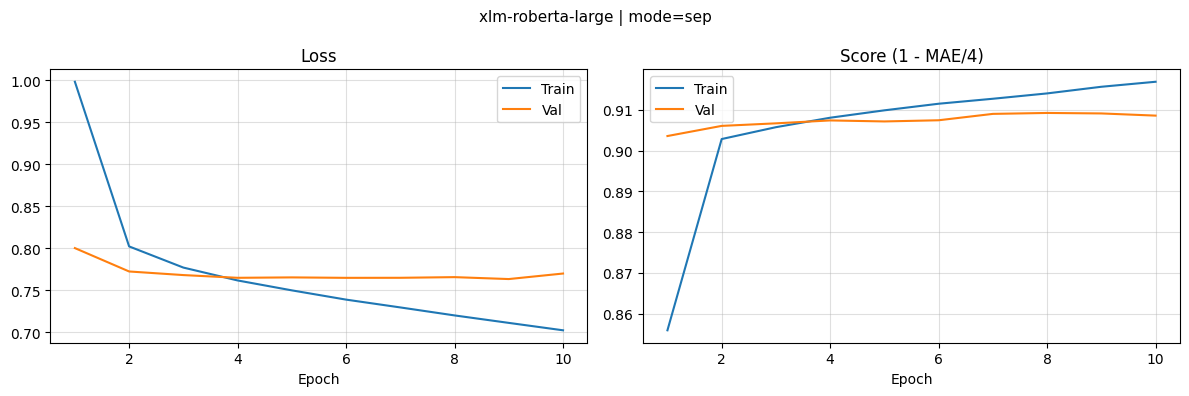

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(train_losses) + 1)

axes[0].plot(epochs, train_losses, label='Train')
axes[0].plot(epochs, val_losses,   label='Val')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.4)

axes[1].plot(epochs, train_scores, label='Train')
axes[1].plot(epochs, val_scores,   label='Val')
axes[1].set_title('Score (1 - MAE/4)'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(alpha=0.4)

plt.suptitle(f'{MODEL_NAME} | mode={PREPROCESSING_MODE}', fontsize=11)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/learning_curves_{ckpt_name}.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
best_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
best_model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
best_model = best_model.to(device)
best_model.eval()

test_predictions = []
with torch.no_grad():
	for batch in tqdm(test_loader, desc='Inference'):
		batch = {k: v.to(device) for k, v in batch.items()}
		batch.pop('labels')
		preds = torch.argmax(best_model(**batch).logits, dim=1).cpu().numpy()
		test_predictions.extend(preds)

submission_df = pd.DataFrame({
	'id':    test_df['id'].astype(int),
	'label': test_predictions,
})
assert len(submission_df) == len(test_df)
assert submission_df['label'].isin([0, 1, 2, 3, 4]).all()

out_path = f'{OUTPUT_DIR}/submission_{ckpt_name}.csv'
submission_df.to_csv(out_path, index=False)
print(f'Submission saved to Drive: {out_path}')
print(submission_df.head(5))

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Inference: 100%|██████████| 2625/2625 [08:17<00:00,  5.28it/s]


Submission saved to Drive: /content/drive/MyDrive/Materials (Spring 2026)/CIL/outputs/submission_xlm-roberta-large_sep_epochs-10_lr-1e-06_bs-64_0525_2018.csv
   id  label
0   0      1
1   1      1
2   2      3
3   3      1
4   4      1


In [ ]:
from google.colab import runtime
runtime.unassign()